# How many people will turn up? Predicting Port Adelaide's home crowds

Crowd size drives a club's match-day revenue, catering and staffing. Can a
simple model predict Port's home attendance at Adelaide Oval, using only things
known before the game?

**Question** ([prediction plan](../docs/prediction_plan_attendance.md), committed
before any model was fitted): how accurately can three things predict Port's home
crowd, and how much better is that than just predicting the average?

- **Recent form:** Port's win % over its previous 10 games (draws count as half),
  running across seasons so round 1 reflects the end of last season.
- **Time slot** (Adelaide local start time; night means a 5pm start or later):
  Thursday or other weeknight, Friday night, Saturday afternoon, Saturday night,
  Sunday afternoon, Sunday night.
- **Showdown:** Port v Adelaide.

**Data:** AFL Tables season pages, which list every match's date, start time, venue and
attendance. Home games are games where Port is the listed home team at Adelaide Oval,
in **2014–2026, leaving out 2020 and 2021** (COVID crowd limits). Finals and
**Gather Round** are left out because the AFL runs their ticketing.

**Validation:** models are compared by **mean absolute error (MAE)** with
leave-one-season-out cross-validation on **2014–2024**. The chosen model is then
scored once on the **2025–2026** games it has never seen.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.analysis import bootstrap
from afl.attendance import gather_rounds, recent_form, season_matches, time_slot
from afl.draft_charts import BLUE, GREY, INK, ORANGE, TITLE, apply_style

# 2013 and 2021 are only needed for recent form at the start of 2014 and 2022
PAGES = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026]
TRAIN = [2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024]
TEST = [2025, 2026]
PORT = "Port Adelaide"
N_BOOT = 2000
SEED = 2026
apply_style()

matches = pd.concat([season_matches(year) for year in PAGES], ignore_index=True)
matches["form"] = recent_form(matches, PORT)  # computed on every match, so form includes away games and finals
gather = gather_rounds(matches)
print("Gather Rounds found:", sorted(gather))

is_home = ((matches["home"] == PORT) & (matches["venue"] == "Adelaide Oval")
           & ~matches["final"] & matches["season"].isin(TRAIN + TEST))
is_gather = pd.Series([(s, r) in gather for s, r in zip(matches["season"], matches["round"])], index=matches.index)
print(f"Port home games at Adelaide Oval in these seasons: {is_home.sum()}, "
      f"of which Gather Round: {(is_home & is_gather).sum()}")

games = matches[is_home & ~is_gather].copy()
games["slot"] = games["start"].map(time_slot)
games["showdown"] = games["away"] == "Adelaide"
games["label"] = (games["season"].astype(str) + " R" + games["round"].str.removeprefix("Round ")
                  + " v " + games["away"])
games = games.sort_values("start").reset_index(drop=True)
train = games[games["season"].isin(TRAIN)].copy()
test = games[games["season"].isin(TEST)].copy()

print(f"Training games: {len(train)}, test games: {len(test)}, missing form: {games['form'].isna().sum()}, "
      f"missing attendance: {games['attendance'].isna().sum()}")
games.groupby("season").size().to_frame("home games").T

Gather Rounds found: [(2023, 'Round 5'), (2024, 'Round 5'), (2025, 'Round 6'), (2026, 'Round 6')]
Port home games at Adelaide Oval in these seasons: 125, of which Gather Round: 4
Training games: 99, test games: 22, missing form: 0, missing attendance: 0


season,2014,2015,2016,2017,2018,2019,2022,2023,2024,2025,2026
home games,11,11,11,11,11,11,11,11,11,11,11


## 1. The crowds

Every home game in the data. Showdowns stand out at around 50,000, close to
Adelaide Oval's capacity. The season averages (black dashes) fell from 2014 to a
low in 2022, then recovered.

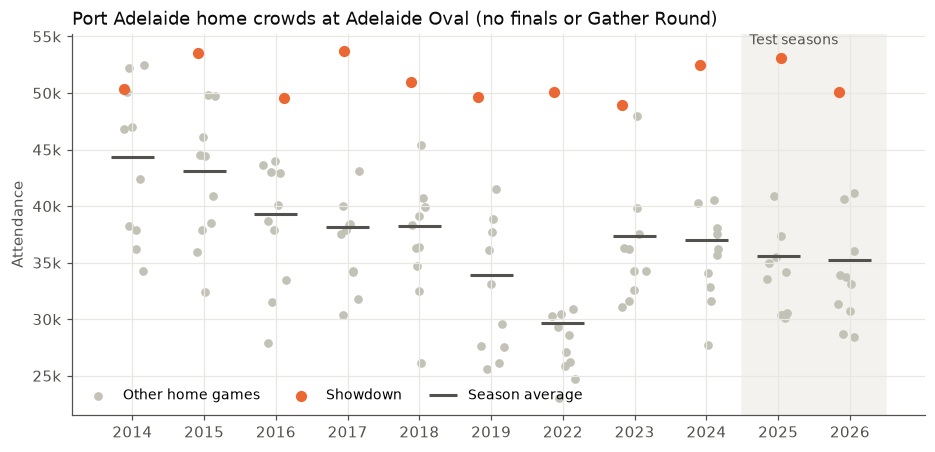

season,2014,2015,2016,2017,2018,2019,2022,2023,2024,2025,2026
season average,44364.0,43086.0,39332.0,38136.0,38227.0,33950.0,29693.0,37336.0,36999.0,35556.0,35263.0


In [2]:
fig, ax = plt.subplots(figsize=(10, 4.5))
seasons = TRAIN + TEST
x_of = {s: i for i, s in enumerate(seasons)}
x = games["season"].map(x_of) + np.random.default_rng(SEED).uniform(-0.18, 0.18, len(games))
other = ~games["showdown"]
ax.scatter(x[other], games.loc[other, "attendance"], s=22, color=GREY, label="Other home games")
ax.scatter(x[~other], games.loc[~other, "attendance"], s=40, color=ORANGE, zorder=3, label="Showdown")
means = games.groupby("season")["attendance"].mean()
ax.hlines(means.values, [x_of[s] - 0.3 for s in means.index], [x_of[s] + 0.3 for s in means.index],
          color=INK, linewidth=2, label="Season average")
ax.axvspan(len(TRAIN) - 0.5, len(seasons) - 0.5, color="#f3f2ee", zorder=0)
ax.annotate("Test seasons", (len(TRAIN) - 0.4, 1.0), xycoords=("data", "axes fraction"),
            va="top", fontsize=9, color=INK)
ax.set_xticks(range(len(seasons)), seasons)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_ylabel("Attendance")
ax.set_title("Port Adelaide home crowds at Adelaide Oval (no finals or Gather Round)",
             loc="left", color=TITLE)
ax.legend(frameon=False, loc="lower left", ncol=3, fontsize=9)
plt.show()
means.round(0).to_frame("season average").T

## 2. What the training seasons show

Training seasons only (2014–2024). Showdowns are left out of these two charts
because they'd swamp everything else.

Training Showdowns: 9, average 51,034; other games: 90, average 36,589
Correlation of recent form with crowd (non-Showdowns): 0.15


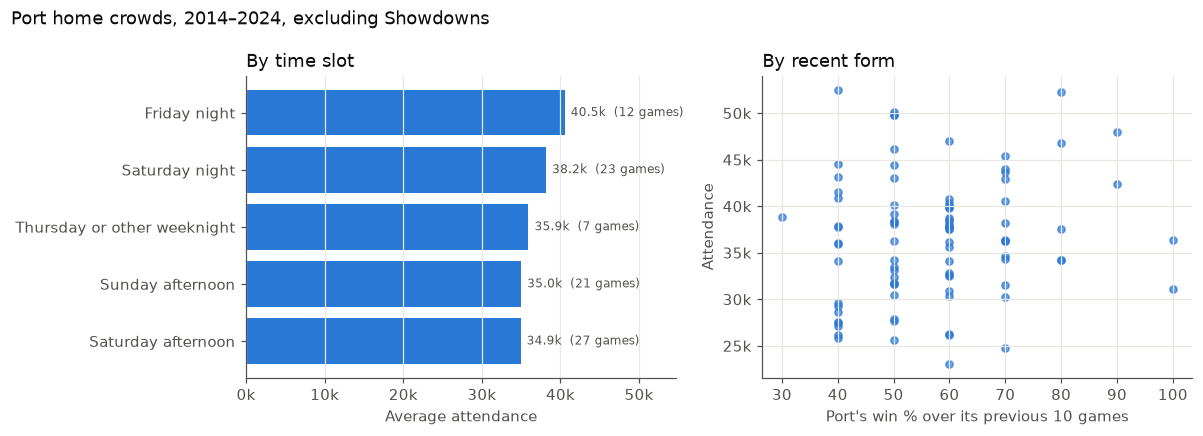

,size,mean
slot,,
Saturday afternoon,27,34920.0
Sunday afternoon,21,34984.0
Thursday or other weeknight,7,35925.0
Saturday night,23,38160.0
Friday night,12,40533.0


In [3]:
plain = train[~train["showdown"]]
print(f"Training Showdowns: {train['showdown'].sum()}, average {train.loc[train['showdown'], 'attendance'].mean():,.0f}; "
      f"other games: {len(plain)}, average {plain['attendance'].mean():,.0f}")
by_slot = plain.groupby("slot")["attendance"].agg(["size", "mean"]).sort_values("mean")
print(f"Correlation of recent form with crowd (non-Showdowns): {plain[['form', 'attendance']].corr().iloc[0, 1]:.2f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1]})
left.barh(by_slot.index, by_slot["mean"], color=BLUE)
for i, (slot, row) in enumerate(by_slot.iterrows()):
    left.annotate(f"{row['mean'] / 1000:.1f}k  ({row['size']:.0f} games)", (row["mean"], i),
                  xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
left.set_xlim(0, by_slot["mean"].max() * 1.35)
left.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
left.set_xlabel("Average attendance")
left.set_title("By time slot", loc="left", color=TITLE)
left.grid(axis="y", visible=False)

right.scatter(plain["form"], plain["attendance"], s=22, color=BLUE, alpha=0.7)
right.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
right.set_xlabel("Port's win % over its previous 10 games")
right.set_ylabel("Attendance")
right.set_title("By recent form", loc="left", color=TITLE)
fig.suptitle("Port home crowds, 2014–2024, excluding Showdowns", x=0.01, ha="left", color=TITLE)
fig.tight_layout()
plt.show()
by_slot.round(0)

## 3. Choosing a model (training seasons only)

Four nested linear regressions, each adding one of the agreed predictors:

| model | predictors |
|---|---|
| Baseline | none: predict the training average for every game |
| A | Showdown |
| B | Showdown + time slot |
| C | Showdown + time slot + recent form |

The time slot enters as one yes/no column per slot, compared with Saturday
afternoon (the most common slot). **Leave-one-season-out cross-validation:**
fit on 8 training seasons, predict the 9th, and repeat for each season. A
model that only memorised the training data would do badly here.

In [4]:
MODELS = ["Baseline", "A", "B", "C"]
SLOTS = ["Saturday night", "Friday night", "Sunday afternoon", "Thursday or other weeknight"]  # vs Saturday afternoon


def features(df: pd.DataFrame, model: str) -> pd.DataFrame:
    """The columns each model uses, plus an intercept."""
    X = pd.DataFrame({"intercept": 1.0}, index=df.index)
    if model in ("A", "B", "C"):
        X["Showdown"] = df["showdown"] * 1.0
    if model in ("B", "C"):
        # No Sunday night games in training, so one would be treated as Sunday afternoon (see plan)
        slot = df["slot"].replace("Sunday night", "Sunday afternoon")
        for s in SLOTS:
            X[s] = (slot == s) * 1.0
    if model == "C":
        X["form"] = df["form"]
    return X


def fit(df: pd.DataFrame, model: str) -> pd.Series:
    """Ordinary least squares coefficients."""
    X = features(df, model)
    coef, *_ = np.linalg.lstsq(X.to_numpy(), df["attendance"].to_numpy(), rcond=None)
    return pd.Series(coef, index=X.columns)


def predict(coef: pd.Series, df: pd.DataFrame, model: str) -> pd.Series:
    return features(df, model) @ coef


cv = []
for season in TRAIN:
    fold_train, fold_test = train[train["season"] != season], train[train["season"] == season]
    for model in MODELS:
        error = predict(fit(fold_train, model), fold_test, model) - fold_test["attendance"]
        cv.append(pd.DataFrame({"season": season, "model": model, "error": error}))
cv = pd.concat(cv)
cv["abs_error"] = cv["error"].abs()

cv_mae = cv.groupby("model")["abs_error"].mean().reindex(MODELS)
CHOSEN = cv_mae.drop("Baseline").idxmin()
print(f"Chosen model (lowest cross-validated MAE): {CHOSEN}")
cv_mae.round(0).to_frame("cross-validated MAE")

Chosen model (lowest cross-validated MAE): A


,cross-validated MAE
model,
Baseline,6296.0
A,5217.0
B,5236.0
C,5255.0


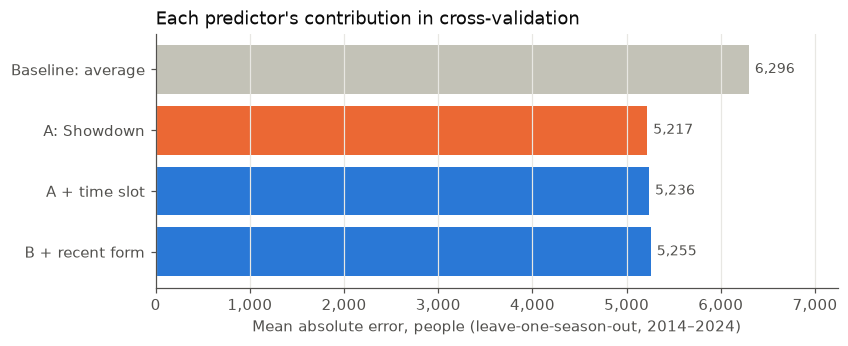

model,Baseline,A,B,C,A: mean error (bias)
season,,,,,
2014,7942.0,7661.0,7629.0,7347.0,-7269.0
2015,6940.0,6463.0,6646.0,7616.0,-5832.0
2016,5293.0,4862.0,5055.0,4762.0,-1608.0
2017,4135.0,3141.0,2866.0,3088.0,-262.0
2018,4607.0,3422.0,2992.0,2821.0,-365.0
2019,7156.0,5682.0,6491.0,6041.0,4447.0
2022,11265.0,9235.0,9362.0,9030.0,9235.0
2023,4795.0,3450.0,3444.0,4178.0,638.0
2024,4533.0,3039.0,2641.0,2411.0,1017.0


In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
colours = [GREY if m == "Baseline" else ORANGE if m == CHOSEN else BLUE for m in MODELS]
names = {"Baseline": "Baseline: average", "A": "A: Showdown", "B": "A + time slot", "C": "B + recent form"}
y = np.arange(len(MODELS))[::-1]
ax.barh(y, cv_mae.values, color=colours)
for yi, value in zip(y, cv_mae.values):
    ax.annotate(f"{value:,.0f}", (value, yi), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_yticks(y, [names[m] for m in MODELS])
ax.set_xlim(0, cv_mae.max() * 1.15)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_xlabel("Mean absolute error, people (leave-one-season-out, 2014–2024)")
ax.set_title("Each predictor's contribution in cross-validation", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
plt.show()

# Where the errors come from: each held-out season's average error (positive = predicted too high)
by_season = cv.pivot_table(index="season", columns="model", values="abs_error", aggfunc="mean")[MODELS].round(0)
by_season[f"{CHOSEN}: mean error (bias)"] = cv[cv["model"] == CHOSEN].groupby("season")["error"].mean().round(0)
by_season

## 4. The chosen model, fitted on all training seasons

Coefficients are in people. Slot coefficients are relative to a Saturday afternoon
game, and form is per 10 percentage points (one extra win in the last 10).

In [6]:
coef = {model: fit(train, model) for model in MODELS}
shown = coef[CHOSEN].copy()
if "form" in shown:
    shown["form"] *= 10
shown = shown.rename({"intercept": "Intercept (non-Showdown Saturday afternoon"
                      + (", 0% form)" if "form" in shown else ")"),
                      "form": "Per extra win in the last 10"})
shown.round(0).to_frame(f"model {CHOSEN}")

,model A
Intercept (non-Showdown Saturday afternoon),36589.0
Showdown,14445.0


## 5. The test: 2025 and 2026

The baseline and the chosen model, both fitted on all 99 training games, predict the
22 home games of 2025 and 2026. These seasons weren't used for any choice above.
The 95% interval for the improvement resamples the 22 test games (2,000 resamples).

In [7]:
for model in MODELS:
    test[f"pred_{model}"] = predict(coef[model], test, model)
    test[f"abs_{model}"] = (test[f"pred_{model}"] - test["attendance"]).abs()

improvement, low, high = bootstrap(test, lambda d: d["abs_Baseline"].mean() - d[f"abs_{CHOSEN}"].mean(),
                                   n=N_BOOT, seed=SEED)
print(f"Test MAE: baseline {test['abs_Baseline'].mean():,.0f}, model {CHOSEN} {test[f'abs_{CHOSEN}'].mean():,.0f}")
print(f"Improvement: {improvement:,.0f} people (95% CI {low:,.0f} to {high:,.0f})")
print(f"Share of test games where model {CHOSEN} beat the baseline: "
      f"{(test[f'abs_{CHOSEN}'] < test['abs_Baseline']).mean():.0%}")

summary = pd.DataFrame({
    "all 22 games": test[[f"abs_{m}" for m in MODELS]].mean(),
    "Showdowns": test.loc[test["showdown"], [f"abs_{m}" for m in MODELS]].mean(),
    "other games": test.loc[~test["showdown"], [f"abs_{m}" for m in MODELS]].mean(),
}).set_axis(MODELS)
print(f"Test Showdowns: {test['showdown'].sum()}; slots: {test['slot'].value_counts().to_dict()}")
normal = test[~test["showdown"]]
print(f"Non-Showdown test games: average crowd {normal['attendance'].mean():,.0f}; "
      f"model {CHOSEN} over-predicted {(normal[f'pred_{CHOSEN}'] > normal['attendance']).sum()} of {len(normal)}")
misses = (test[f"pred_{CHOSEN}"] - test["attendance"]).abs().sort_values(ascending=False).head(2)
for i, miss in misses.items():
    print(f"  Big miss: {test.at[i, 'label']}: actual {test.at[i, 'attendance']:,.0f}, off by {miss:,.0f}")
summary.round(0)

Test MAE: baseline 5,798, model A 3,923
Improvement: 1,875 people (95% CI 648 to 3,535)
Share of test games where model A beat the baseline: 82%
Test Showdowns: 2; slots: {'Saturday night': 8, 'Sunday afternoon': 6, 'Saturday afternoon': 5, 'Friday night': 2, 'Thursday or other weeknight': 1}
Non-Showdown test games: average crowd 33,790; model A over-predicted 16 of 20
  Big miss: 2026 R24 v Melbourne: actual 28,417, off by 8,172
  Big miss: 2026 R20 v Fremantle: actual 28,727, off by 7,862


,all 22 games,Showdowns,other games
Baseline,5798.0,13699.0,5008.0
A,3923.0,1515.0,4164.0
B,3533.0,1515.0,3735.0
C,3063.0,725.0,3296.0


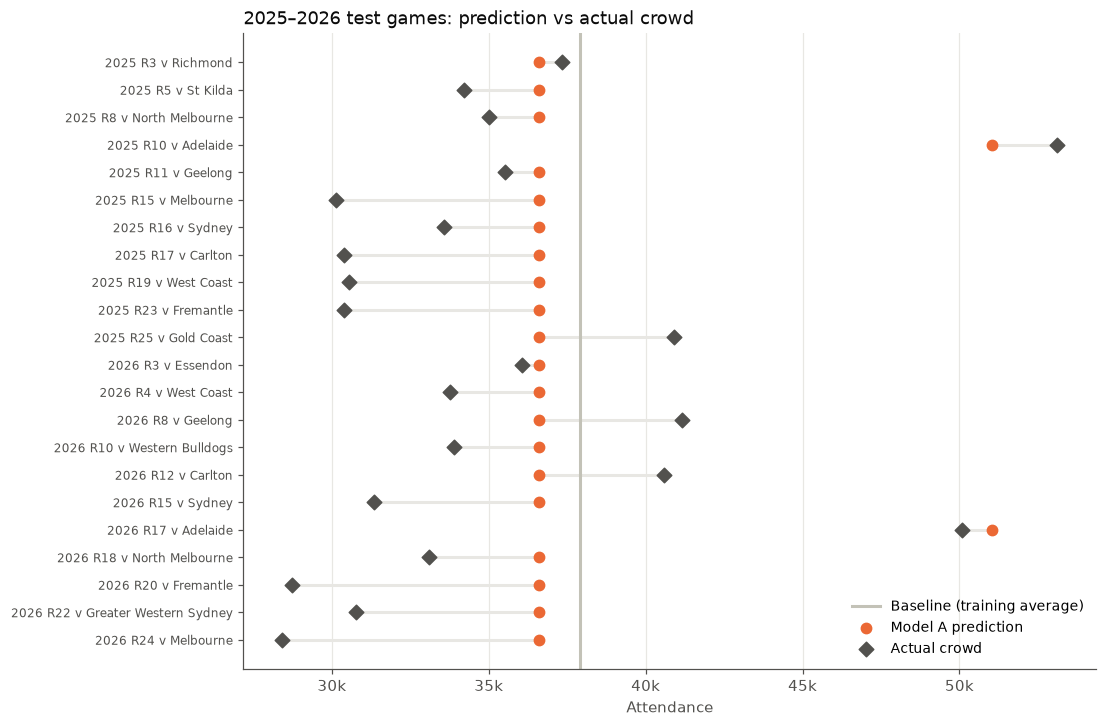

,label,slot,form,attendance,pred_Baseline,pred_A
99,2025 R3 v Richmond,Saturday afternoon,70.0,37342.0,37903.0,36589.0
100,2025 R5 v St Kilda,Sunday afternoon,60.0,34201.0,37903.0,36589.0
101,2025 R8 v North Melbourne,Saturday afternoon,50.0,35004.0,37903.0,36589.0
102,2025 R10 v Adelaide,Saturday night,50.0,53117.0,37903.0,51034.0
103,2025 R11 v Geelong,Saturday afternoon,40.0,35508.0,37903.0,36589.0
104,2025 R15 v Melbourne,Sunday afternoon,40.0,30144.0,37903.0,36589.0
105,2025 R16 v Sydney,Saturday afternoon,50.0,33576.0,37903.0,36589.0
106,2025 R17 v Carlton,Thursday or other weeknight,50.0,30381.0,37903.0,36589.0
107,2025 R19 v West Coast,Sunday afternoon,40.0,30553.0,37903.0,36589.0
108,2025 R23 v Fremantle,Saturday night,40.0,30390.0,37903.0,36589.0


In [8]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ordered = test.sort_values("start")
y = np.arange(len(ordered))[::-1]
ax.axvline(coef["Baseline"]["intercept"], color=GREY, linewidth=2, label="Baseline (training average)")
ax.hlines(y, ordered[f"pred_{CHOSEN}"], ordered["attendance"], color="#e8e7e3", linewidth=2, zorder=1)
ax.scatter(ordered[f"pred_{CHOSEN}"], y, s=45, color=ORANGE, zorder=3, label=f"Model {CHOSEN} prediction")
ax.scatter(ordered["attendance"], y, s=45, color=INK, marker="D", zorder=3, label="Actual crowd")
ax.set_yticks(y, ordered["label"], fontsize=8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Attendance")
ax.set_title("2025–2026 test games: prediction vs actual crowd", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.show()

ordered[["label", "slot", "form", "attendance", "pred_Baseline", f"pred_{CHOSEN}"]].round(0)

# Results

## Data

- **125 Port home games at Adelaide Oval** in 2014–2019 and 2022–2026, outside
  finals. **4 were in Gather Round** and are left out, leaving **121: 99 for training
  (11 a season, 2014–2024) and 22 for testing (2025–2026)**.
- In training, the **9 Showdowns averaged 51,034** and the other **90 games 36,589**.
  The season average fell from **44,364 in 2014** to **29,693 in 2022**, then
  recovered to about 37,000 in 2023–2024.

## The answer: the Showdown is the only predictor that clearly earns its place

- **Cross-validation (2014–2024):** predicting the average for every game misses by
  **6,296** people on average. Adding the Showdown flag (model A) cuts that to **5,217**.
  Adding time slot (**5,236**) and then recent form (**5,255**) made it very slightly
  *worse*, so **model A was chosen**, as the plan specified.
- **Model A is simply:** predict **36,589** for a normal home game and **51,034**
  (**+14,445**) for a Showdown.
- **On the unseen 2025–2026 games**, model A's MAE was **3,923**, against **5,798**
  for the baseline. That's **1,875 fewer people of error per game (95% CI 648 to
  3,535)**. It beat the baseline in **82%** of the 22 games. Most of the gain is
  the two Showdowns: an average miss of **1,515** against **13,699**. For other
  games, the MAE was **4,164** against **5,008**.

## Time slot and form: real patterns, but small and unreliable

- Night games did draw more in training. Friday nights averaged **40.5k** and
  Saturday nights **38.2k**, against **34.9k** for Saturday afternoons (excluding
  Showdowns). Recent form barely moved crowds (correlation **0.15**).
- But in cross-validation, neither improved predictions for a season the model
  hadn't seen. **On the test seasons they did help** (MAE **3,533** with slot,
  **3,063** with slot and form). That conflicts with cross-validation, and 22
  games is a small test, so the safe reading is "maybe a little", not "yes".

## Where the errors come from: whole seasons, not individual games

- Model A's biggest cross-validation misses are **season-wide**. It
  **over-predicted 2022 by 9,235 a game on average**, and under-predicted 2014 by
  **7,269** and 2015 by **5,832**. None of the three predictors captures a whole
  season being up or down.
- The test seasons show the same thing on a smaller scale. Normal home games
  averaged **33,790** in 2025–2026, about 2,800 below the training average, so
  model A over-predicted **16 of the 20** non-Showdown games. Its biggest misses
  were 2026 R24 v Melbourne (28,417, over by 8,172) and 2026 R20 v Fremantle
  (28,727, over by 7,862).

## In one line

**For Port home crowds, knowing whether it's a Showdown matters far more than
the time slot or how Port is going: a Showdown adds about 14,000 people.** The
remaining error is mostly season-to-season swings in Port's whole crowd.

## Caveats and next steps

- **Small samples:** 9 training Showdowns and 22 test games. The test
  interval (648 to 3,535) is wide.
- **The 2025–2026 attendances had been printed** while checking the page layout,
  before the plan was written (the plan says so). No model was fitted or compared
  on them before the plan was committed.
- **Untested ideas** (outside the agreed spec): a season-level predictor such as
  membership numbers or last season's average crowd could target the biggest
  source of error. The opponent (e.g. Collingwood or Richmond bringing big
  travelling crowds) is another.